# Multilabel Image Classification with a pre-trained ResNet



## 1. Set Up

Install the Python dependencies in your notebook environment:  
`python -m pip install ipykernel numpy pandas matplotlib pillow scikit-learn "mlflow>=3,<4"`

Install `torch` and `torchvision` using the [PyTorch installer](https://pytorch.org/get-started/locally/). If running locally on your graphics card, select your OS and a CUDA build.

The link to the data is [here](https://www.kaggle.com/datasets/nih-chest-xrays/sample). Download the data from kaggle. The `images` folder should have all 5,606 png files in it. Place the `images/` folder directly inside the repo's `data/` directory. The repo already includes the CSV. From `notebooks/`, the paths are `../data/sample_labels.csv` and `../data/images/`. Run the notebook from the repo root or from `notebooks/`.

First we start by reading in the data, doing initial checks on it, and setting up PyTorch.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image

cwd = Path.cwd().resolve()
repo_dir = cwd.parent if cwd.name == "notebooks" else cwd
data_dir = repo_dir / "data"
labels_path = data_dir / "sample_labels.csv"
images_dir = data_dir / "images"
output_dir = repo_dir / "outputs"

if not labels_path.is_file():
    raise FileNotFoundError(
        f"Missing {labels_path}. Run the notebook from the repo root or notebooks/."
    )
if not images_dir.is_dir():
    raise FileNotFoundError(f"Place the 5,606 PNGs in {images_dir}.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Images:", images_dir)
print("Outputs:", output_dir)
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

Images: C:\Users\posit\Desktop\pstat-fall\pstat-197a\vignette-image-classification\data\images
Outputs: C:\Users\posit\Desktop\pstat-fall\pstat-197a\vignette-image-classification\outputs
Device: NVIDIA GeForce RTX 3080


## 2. Match images to labels

Here, we clean the label table, then match each row to a PNG by filename. A label such as `Effusion|Atelectasis` means both findings were recorded for that image. The example below shows one image with its recorded findings. Any issues with the data will raise an error describing the issue.

Matched 5,606 images from 4,230 patients.


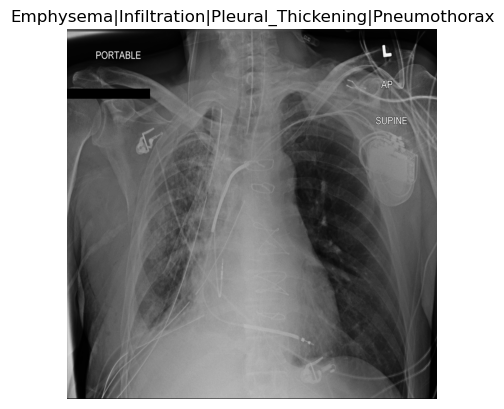

In [2]:
# Import label csv
labels = pd.read_csv(
    labels_path,
    dtype={"Patient ID": str},
)
labels.columns = labels.columns.str.strip()

required_columns = ["Patient ID", "Image Index", "Finding Labels"]
for column in required_columns:
    labels[column] = labels[column].str.strip().replace("", pd.NA)
if labels[required_columns].isna().any().any():
    raise ValueError("Missing patient ID, image filename, or finding label.")

findings = [
    "Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Effusion",
    "Emphysema", "Fibrosis", "Hernia", "Infiltration", "Mass", "Nodule",
    "Pleural_Thickening", "Pneumonia", "Pneumothorax",
]
labels["Finding Labels"] = labels["Finding Labels"].map(
    lambda value: "|".join(sorted({label.strip() for label in value.split("|")}))
)
observed = set(labels["Finding Labels"].str.split("|").explode())
unexpected = observed - {*findings, "No Finding"}
if unexpected:
    raise ValueError(f"Unexpected finding labels: {sorted(unexpected)}")

conflicts = labels["Finding Labels"].str.contains("No Finding", regex=False) & (
    labels["Finding Labels"] != "No Finding"
)
if conflicts.any():
    raise ValueError("'No Finding' is combined with another finding.")

labels = labels.drop_duplicates().reset_index(drop=True)
if labels["Image Index"].duplicated().any():
    raise ValueError("Multiple metadata rows remain for the same image.")

# Match each CSV filename to a file directly inside images/.
labels["image_path"] = labels["Image Index"].map(lambda name: images_dir / name)
missing = ~labels["image_path"].map(Path.is_file)
if missing.any():
    raise FileNotFoundError(
        f"{missing.sum():,} labeled images are missing from {images_dir}. "
        f"First missing file: {labels.loc[missing, 'Image Index'].iloc[0]}"
    )

print(f"Matched {len(labels):,} images from {labels['Patient ID'].nunique():,} patients.")
row = labels.iloc[0]
with Image.open(row["image_path"]) as image:
    plt.imshow(image.convert("L"), cmap="gray")
plt.title(row["Finding Labels"])
plt.axis("off")
plt.show()

## 3. Encode all 14 findings and split by patient

Here we create one binary target column per finding. An image labeled `No Finding` has zeros in all 14 columns. Keep all images from a patient in the same partition so repeat exams from that patient cannot appear on both sides of the evaluation.

We split patients approximately 70%/15%/15% into train, validation, and test. Seed 1 was chosen for label coverage so that every finding has positive patients in each partition. Validation patients are used to choose regularization. The test patients are used to evaluate the selected model. This cell outputs the size of the training, validation, and test set, as well as the amount of each finding in those sets.

In [3]:
from sklearn.model_selection import GroupShuffleSplit

# Create column for each finding label, excluding "No Finding"
targets = labels["Finding Labels"].str.get_dummies(sep="|")[findings]

# Used for grouping by patients
patients = labels["Patient ID"]

# Hold out 30% of patients, divide those patients equally
seed = 1
train_idx, held_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed)
    .split(targets, groups=patients)
)

# Split the held-out patients into validation and test sets
val_pos, test_pos = next(
    GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=seed)
    .split(targets.iloc[held_idx], groups=patients.iloc[held_idx])
)

# Create a dictionary to hold the indices for each split
splits = {
    "train": train_idx,
    "validation": held_idx[val_pos],
    "test": held_idx[test_pos],
}

# Check patient separation and verify that every label can be fit and evaluated.
for split, idx in splits.items():
    counts = targets.iloc[idx].sum()
    if ((counts == 0) | (counts == len(idx))).any():
        raise ValueError(f"At least one finding is missing a class in {split}.")

patient_sets = [set(patients.iloc[idx]) for idx in splits.values()]
if sum(map(len, patient_sets)) != patients.nunique():
    raise ValueError("Patient overlap across splits.")

# Count patients with at least one positive image per finding.
positive_patients = pd.DataFrame({
    split: targets.iloc[idx].groupby(patients.iloc[idx]).max().sum()
    for split, idx in splits.items()
})

print({split: len(idx) for split, idx in splits.items()})
display(positive_patients.sort_values("test"))

{'train': 3905, 'validation': 846, 'test': 855}


,train,validation,test
Hernia,8,2,3
Pneumonia,40,11,8
Edema,81,15,13
Emphysema,84,17,13
Fibrosis,52,13,15
Cardiomegaly,89,17,20
Pleural_Thickening,113,27,24
Pneumothorax,171,26,29
Consolidation,137,28,33
Mass,176,50,35


## 4. Extract or reload frozen ResNet-18 features

Here, we use the preprocessing supplied by the ImageNet weights and replace the final classification layer with an identity layer. The network then returns 512 features per image. The first run checks a small batch and caches the full matrix in `outputs/resnet18_imagenet1k_v1.npz`. On later runs the notebook checks the stored filenames and aligns the cache to the label table. Delete the cache or change its filename if you change the preprocessing or backbone.

The cell below outputs the dimensions of the feature matrix `X` (5606 rows, 512 columns), where each row is an image and each column is a feature.

In [4]:
from time import perf_counter

from torch import nn
from torchvision.models import ResNet18_Weights, resnet18

# Load pre-trained weights
weights = ResNet18_Weights.IMAGENET1K_V1

# Load preprocessing function to resize images
preprocess = weights.transforms()

cache_path = output_dir / "resnet18_imagenet1k_v1.npz"
image_ids = labels["Image Index"].to_numpy(dtype=str)
feature_count = 512
batch_size = 8

if not cache_path.is_file():
    backbone = resnet18(weights=weights)
    backbone.fc = nn.Identity()
    backbone = backbone.to(device).eval()

    def extract_batch(paths):
        tensors = []
        for path in paths:
            with Image.open(path) as image:
                tensors.append(preprocess(image.convert("RGB")))
        with torch.inference_mode():
            return backbone(torch.stack(tensors).to(device)).cpu().numpy()

    paths = labels["image_path"].tolist()
    features = np.empty((len(paths), feature_count), dtype=np.float32)
    started = perf_counter()

    for start in range(0, len(paths), batch_size):
        stop = min(start + batch_size, len(paths))
        batch = extract_batch(paths[start:stop])
        if batch.shape != (stop - start, feature_count) or not np.isfinite(batch).all():
            raise ValueError(f"Invalid features for images {start} through {stop - 1}.")
        features[start:stop] = batch
        if start == 0:
            print("First batch feature shape:", batch.shape)
        if stop == 128:
            minutes = (perf_counter() - started) * len(paths) / stop / 60
            print(f"Estimated total extraction time: {minutes:.1f} minutes")

    cache_path.parent.mkdir(parents=True, exist_ok=True)
    partial_path = cache_path.with_suffix(".partial.npz")
    np.savez_compressed(partial_path, features=features, image_ids=image_ids)
    partial_path.replace(cache_path)
    print("Saved features to", cache_path)

with np.load(cache_path, allow_pickle=False) as cache:
    cached_features = cache["features"]
    cached_ids = pd.Index(cache["image_ids"])

if not cached_ids.is_unique or cached_features.shape != (len(cached_ids), feature_count):
    raise ValueError(f"Invalid feature cache: {cache_path}. Delete it and run this cell again.")

positions = cached_ids.get_indexer(image_ids)
if len(cached_ids) != len(image_ids) or (positions < 0).any():
    raise ValueError(f"The cached IDs do not match this dataset. Rebuild {cache_path}.")

X = cached_features[positions]
if not np.isfinite(X).all():
    raise ValueError(f"Nonfinite features found in {cache_path}. Rebuild the cache.")

print("Feature matrix:", X.shape)
display(pd.DataFrame(X[:5, :5], index=image_ids[:5]))

Feature matrix: (5606, 512)


,0,1,2,3,4
00000013_005.png,0.548919,1.373074,0.106984,4.269087,1.550608
00000013_026.png,1.062297,0.845564,0.164993,4.111717,0.806138
00000017_001.png,0.895328,1.649905,0.448787,4.752702,0.534809
00000030_001.png,0.669146,0.791341,0.144831,3.792386,0.705385
00000032_001.png,0.846279,0.768390,0.108796,3.147635,0.517341


## 5. Fit and compare regularization settings

Below, we standardize the features using the training images, then fit a binary logistic regression for each finding. One parameter we want to tune for is regularization strength, `C`. Smaller `C` means stronger regularization. We will compare all eight settings in one sweep.

For multilabel classification, an important statistic is **Average precision (AP)**. Average precision summarizes the ranking across the precision–recall curve. A naive classifier has AP equal to the fraction of positive images for that finding, denoted as the finding's prevalence. **Macro AP** is the unweighted mean of the 14 per-finding AP scores. We pick one shared `C` by validation macro AP. If two settings tie exactly, we choose the smaller `C`. We compare the training and validation scores to see how the model generalizes. If there is a significant gap between training and validation AP, that is a sign of overfitting, so we also ideally would have a low gap between training and validation AP.

[MLflow](https://mlflow.org/docs/latest/ml/tracking/) saves each run's settings and AP scores. The notebook stores the database and artifacts in `outputs/tracking.db` and `outputs/mlflow_artifacts/`, respectively.

In [6]:
import mlflow
import mlflow.sklearn

output_dir.mkdir(exist_ok=True)

# Set the MLflow tracking URI to a SQLite database in outputs/.
mlflow.set_tracking_uri(f"sqlite:///{(output_dir / 'tracking.db').as_posix()}")
experiment_name = "nih-xray-multilabel"

# Create the experiment if it doesn't exist, and set it as the active experiment
if mlflow.get_experiment_by_name(experiment_name) is None:
    mlflow.create_experiment(
        experiment_name,
        artifact_location=(output_dir / "mlflow_artifacts").as_uri(),
    )

mlflow.set_experiment(experiment_name)

<Experiment: artifact_location='file:///C:/Users/posit/Desktop/pstat-fall/pstat-197a/vignette-image-classification/outputs/mlflow_artifacts', creation_time=1795692297726, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1795692297726, lifecycle_stage='active', name='nih-xray-multilabel', tags={}, trace_location=None, workspace='default'>

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_train, X_val = X[splits["train"]], X[splits["validation"]]
y_train = targets.iloc[splits["train"]]
y_val = targets.iloc[splits["validation"]]
print("Training features and targets:", X_train.shape, y_train.shape)

c_values = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.1, 1.0, 10.0]
models_by_c = {}
comparison_tables = []
model_params = {
    "backbone": "resnet18",
    "weights": weights.name,
    "split_seed": seed,
    "solver": "lbfgs",
    "max_iter": 1000,
    "class_weight": "none",
    "feature_scaling": "StandardScaler",
}

for c in c_values:
    model = make_pipeline(
        StandardScaler(),
        OneVsRestClassifier(LogisticRegression(C=c, solver="lbfgs", max_iter=1000)),
    )
    with mlflow.start_run(run_name=f"resnet18-logreg-C-{c:g}"):
        mlflow.log_params({**model_params, "C": c})
        model.fit(X_train, y_train)

        scores = pd.DataFrame({
            "finding": findings,
            "C": c,
            "train_positives": y_train.sum().to_numpy(),
            "val_positives": y_val.sum().to_numpy(),
            "val_prevalence": y_val.mean().to_numpy(),
            "train_ap": average_precision_score(
                y_train, model.predict_proba(X_train), average=None
            ),
            "val_ap": average_precision_score(
                y_val, model.predict_proba(X_val), average=None
            ),
        })
        scores["train_val_gap"] = scores["train_ap"] - scores["val_ap"]
        metrics = {
            "train_macro_ap": float(scores["train_ap"].mean()),
            "val_macro_ap": float(scores["val_ap"].mean()),
        }
        for row in scores.itertuples(index=False):
            label = row.finding.lower()
            metrics[f"train_ap_{label}"] = float(row.train_ap)
            metrics[f"val_ap_{label}"] = float(row.val_ap)

        mlflow.log_metrics(metrics)
        mlflow.log_text(scores.to_csv(index=False), "per_label_metrics.csv")

    comparison_tables.append(scores)
    models_by_c[c] = model

tuning_results = pd.concat(comparison_tables, ignore_index=True)
summary = (
    tuning_results.groupby("C", as_index=False)
    .agg(
        train_macro_ap=("train_ap", "mean"),
        val_macro_ap=("val_ap", "mean"),
        mean_gap=("train_val_gap", "mean"),
    )
    .sort_values(["val_macro_ap", "C"], ascending=[False, True])
)
display(summary.round(4))
display(tuning_results.pivot(index="finding", columns="C", values="val_ap").round(4))

Training features and targets: (3905, 512) (3905, 14)


,C,train_macro_ap,val_macro_ap,mean_gap
3,0.0030,0.3264,0.1322,0.1942
2,0.0010,0.2442,0.1304,0.1138
4,0.0100,0.4656,0.1269,0.3387
1,0.0003,0.1922,0.1241,0.0681
0,0.0001,0.1674,0.1197,0.0477
5,0.1000,0.7310,0.1192,0.6118
6,1.0000,0.8340,0.1028,0.7312
7,10.0000,0.8670,0.1006,0.7665


C,0.0001,0.0003,0.0010,0.0030,0.0100,0.1000,1.0000,10.0000
finding,,,,,,,,
Atelectasis,0.1630,0.1780,0.1909,0.1950,0.1938,0.1727,0.1672,0.1631
Cardiomegaly,0.0530,0.0540,0.0576,0.0558,0.0549,0.0536,0.0506,0.0511
Consolidation,0.0715,0.0747,0.0798,0.0845,0.0832,0.0649,0.0570,0.0641
Edema,0.0833,0.0869,0.1113,0.1108,0.1073,0.0644,0.0541,0.0464
Effusion,0.2973,0.3077,0.3056,0.2991,0.2856,0.2475,0.2185,0.2129
Emphysema,0.0589,0.0637,0.0755,0.1007,0.1252,0.1147,0.1010,0.1001
Fibrosis,0.0458,0.0455,0.0440,0.0419,0.0356,0.0251,0.0232,0.0236
Hernia,0.0595,0.0636,0.0575,0.0709,0.0944,0.2560,0.1694,0.1688
Infiltration,0.2536,0.2627,0.2735,0.2714,0.2650,0.2470,0.2404,0.2398


In the recorded run, `C = 0.003` produced the highest validation macro AP. The next cell selects the best setting from the validation results of the current run.

## 6. Evaluate the selected model on held-out patients

Here we use the fitted pipeline with the highest validation macro AP to score the test patients. We Report AP, prevalence, and positive image and patient counts for each finding. The selected pipeline, label order, split assignments, and test results are saved in MLflow so we can reload and evaluate the model without having to rerun the computationally expensive code chunks.

In [8]:
# Select the best regularization parameter and corresponding model
selected_c = float(summary.iloc[0]["C"])
selected_model = models_by_c[selected_c]
test_idx = splits["test"]

# Evaluate the selected model on the test set and log results to MLflow
X_test = X[test_idx]
y_test = targets.iloc[test_idx]
test_patients = labels.iloc[test_idx]["Patient ID"].to_numpy()

test_scores = selected_model.predict_proba(X_test)
positive_patients = y_test.groupby(test_patients).max().sum()

test_results = pd.DataFrame({
    "finding": y_test.columns.tolist(),
    "test_positive_images": y_test.sum().to_numpy(),
    "test_positive_patients": positive_patients.to_numpy(),
    "test_prevalence": y_test.mean().to_numpy(),
    "test_ap": average_precision_score(y_test, test_scores, average=None),
})

split_manifest = pd.concat(
    [
        labels.iloc[idx][["Image Index", "Patient ID"]].assign(split=split_name)
        for split_name, idx in splits.items()
    ],
    ignore_index=True,
)

with mlflow.start_run(run_name="resnet18-logreg-selected-test") as run:
    mlflow.log_params({
        **model_params,
        "C": selected_c,
        "selection_metric": "validation_macro_ap",
        "test_images": len(y_test),
    })
    mlflow.log_metrics({
        "val_macro_ap": float(summary.iloc[0]["val_macro_ap"]),
        "test_macro_ap": float(test_results["test_ap"].mean()),
        "test_macro_prevalence": float(test_results["test_prevalence"].mean()),
    })
    for row in test_results.itertuples(index=False):
        mlflow.log_metric(f"test_ap_{row.finding.lower()}", float(row.test_ap))

    mlflow.log_text(test_results.to_csv(index=False), "test_metrics.csv")
    mlflow.log_text(split_manifest.to_csv(index=False), "split_manifest.csv")
    mlflow.log_dict({"label_order": y_test.columns.tolist()}, "labels.json")
    model_info = mlflow.sklearn.log_model(selected_model, name="classifier", serialization_format="cloudpickle")

print("Selected C:", selected_c)
print("Test macro AP:", round(test_results["test_ap"].mean(), 4))
print("Test macro prevalence:", round(test_results["test_prevalence"].mean(), 4))
print("MLflow run ID:", run.info.run_id)
print("Saved model URI:", model_info.model_uri)
display(test_results.sort_values("test_ap", ascending=False).round(4))

2026/11/26 03:25:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Selected C: 0.003
Test macro AP: 0.1395
Test macro prevalence: 0.0518
MLflow run ID: 27743e716e474ec7a1ee00f9a391635e
Saved model URI: models:/m-7b1998d59a464f9fbe3624e91d93bf5e


,finding,test_positive_images,test_positive_patients,test_prevalence,test_ap
4,Effusion,103,88,0.1205,0.2943
8,Infiltration,156,135,0.1825,0.2816
0,Atelectasis,93,83,0.1088,0.2333
3,Edema,15,13,0.0175,0.2263
13,Pneumothorax,36,29,0.0421,0.2047
9,Mass,37,35,0.0433,0.1621
1,Cardiomegaly,24,20,0.0281,0.1211
10,Nodule,50,46,0.0585,0.0909
2,Consolidation,37,33,0.0433,0.0908
11,Pleural_Thickening,26,24,0.0304,0.0676


### Reload the fitted pipeline

The saved scikit-learn pipeline takes the 512-dimensional ResNet features as input and includes the fitted scaler and all 14 classifiers. Use the printed model URI with access to the same MLflow store. Load model artifacts from runs you trust. For new X-rays, first apply the same pretrained ResNet and preprocessing from section 4. Read `labels.json` from the logged run to identify the probability columns.

In [9]:
reloaded_model = mlflow.sklearn.load_model(model_info.model_uri)
reloaded_scores = reloaded_model.predict_proba(X_test[:5])
np.testing.assert_allclose(reloaded_scores, test_scores[:5])
print("Reloaded model matches the saved run on the first five test images.")

Reloaded model matches the saved run on the first five test images.


## 7. Interpret the results

In the original Jetstream run, `C=0.003` had the highest validation macro AP (0.1322, compared with 0.1029 for `C=1`). The selected model's test macro AP was **0.1394**, compared with a **0.0518** mean test prevalence. All 14 findings scored above their prevalence baselines on that split. The cells above report the results for the run.

Effusion had the highest absolute test AP (0.2940). Edema and Pneumothorax also showed large improvements over their prevalence baselines. Hernia is included in the table, and its AP comes from only three positive test patients, so it can change substantially if one patient's images move in the ranking. The results describe ranking performance against the NIH sample's report-derived labels.